# Late Night Phone Habits Analysis and Fatigue Prediction
## Deliverable 1 – Data Analysis Report

---
# CLO1: Introduction and Data Wrangling

### Import libraries and load the dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("samartalwar/sleep-debt-and-screen-time-late-night-phone-habits")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Zain Faisal\.cache\kagglehub\datasets\samartalwar\sleep-debt-and-screen-time-late-night-phone-habits\versions\1


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv(os.path.join(path, 'bedtime_screentime_sleep_debt.csv'))

print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


### Structure of the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Missing values per column:
user_id                     0
age                         0
gender                      0
occupation_type             0
chronotype                  0
bedtime_phone_minutes       0
primary_bedtime_app         0
screen_brightness_pct       0
blue_light_filter_active    0
caffeine_post_5pm_mg        0
physical_activity_min       0
sleep_latency_min           0
total_sleep_hours           0
deep_sleep_pct              0
rem_sleep_pct               0
morning_alarm_snoozes       0
next_day_fatigue_score      0
sleep_debt_category         0
dtype: int64

Duplicate records: 0


### Numerical and categorical variables

In [5]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
categorical_cols.remove("user_id")               # identifier only, not used in analysis

print("Numerical variables  :", numerical_cols)
print("Categorical variables:", categorical_cols)

Numerical variables  : ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
Categorical variables: ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'sleep_debt_category']


### Identify dependent and independent variables

In [6]:
dependent_var = "next_day_fatigue_score"
independent_vars = [c for c in df.columns if c not in ["user_id", dependent_var]]

X = df[independent_vars]
y = df[dependent_var]

print("Dependent variable (y):", dependent_var)
print("Independent variables (X):", independent_vars)
print("Number of independent variables:", len(independent_vars))
print("X shape:", X.shape, "| y shape:", y.shape)

# Main independent variable (used for scatter plot, correlation and simple regression)
main_independent = "bedtime_phone_minutes"
print("\nMain independent variable:", main_independent)

Dependent variable (y): next_day_fatigue_score
Independent variables (X): ['age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'sleep_debt_category']
Number of independent variables: 16
X shape: (8500, 16) | y shape: (8500,)

Main independent variable: bedtime_phone_minutes


### Sampling decision

In [7]:
population_size = len(df)
sample_size = 150

print("Population size:", population_size)
print("Sample size    :", sample_size)

Population size: 8500
Sample size    : 150


---
# CLO2: Descriptive, Exploratory and Statistical Analysis

### Script for Descriptive Analysis
Function takes the **sample** and the **field** as input and returns its descriptive statistics.

In [8]:
def descriptive_stats(sample, field):
    data = sample[field]
    stats_dict = {
        "Count": data.count(),
        "Mean": data.mean(),
        "Median": data.median(),
        "Mode": data.mode()[0],
        "Standard Deviation": data.std(),
        "Variance": data.var(),
        "Minimum": data.min(),
        "Maximum": data.max(),
        "Range": data.max() - data.min(),
        "Q1 (25%)": data.quantile(0.25),
        "Q3 (75%)": data.quantile(0.75),
        "IQR": data.quantile(0.75) - data.quantile(0.25),
        "Skewness": data.skew(),
        "Kurtosis": data.kurt()
    }
    return pd.Series(stats_dict, name=field).round(3)

### Random Sampling (n = 150)

In [9]:
random_sample = df.sample(n=150, random_state=42)

print("Random sample size:", len(random_sample))
print("\nDescriptive statistics of", dependent_var, "(Random Sample):")
print(descriptive_stats(random_sample, dependent_var))

Random sample size: 150

Descriptive statistics of next_day_fatigue_score (Random Sample):
Count                 150.000
Mean                    3.648
Median                  3.150
Mode                    1.000
Standard Deviation      2.595
Variance                6.734
Minimum                 1.000
Maximum                10.000
Range                   9.000
Q1 (25%)                1.000
Q3 (75%)                5.200
IQR                     4.200
Skewness                0.759
Kurtosis               -0.406
Name: next_day_fatigue_score, dtype: float64


### Systematic Sampling (with condition)
Condition: users who used their phone for **30 minutes or more** before bed. From these users every k-th record is selected to get 150 records.

In [10]:
condition_df = df[df["bedtime_phone_minutes"] >= 30].reset_index(drop=True)

n = 150
k = max(len(condition_df) // n, 1)      # sampling interval
start = 0                                # starting point

systematic_sample = condition_df.iloc[start::k].head(n)

print("Records meeting the condition:", len(condition_df))
print("Sampling interval (k):", k)
print("Systematic sample size:", len(systematic_sample))
print("\nDescriptive statistics of", dependent_var, "(Systematic Sample):")
print(descriptive_stats(systematic_sample, dependent_var))

Records meeting the condition: 6573
Sampling interval (k): 43
Systematic sample size: 150

Descriptive statistics of next_day_fatigue_score (Systematic Sample):
Count                 150.000
Mean                    4.611
Median                  4.300
Mode                    1.000
Standard Deviation      2.605
Variance                6.785
Minimum                 1.000
Maximum                10.000
Range                   9.000
Q1 (25%)                2.425
Q3 (75%)                6.475
IQR                     4.050
Skewness                0.398
Kurtosis               -0.785
Name: next_day_fatigue_score, dtype: float64


### Descriptive Statistical Report (Dependent Variable – full dataset)

In [11]:
print("Descriptive statistics of", dependent_var, "(Full Dataset):")
print(descriptive_stats(df, dependent_var))

Descriptive statistics of next_day_fatigue_score (Full Dataset):
Count                 8500.000
Mean                     3.795
Median                   3.200
Mode                     1.000
Standard Deviation       2.685
Variance                 7.210
Minimum                  1.000
Maximum                 10.000
Range                    9.000
Q1 (25%)                 1.100
Q3 (75%)                 5.600
IQR                      4.500
Skewness                 0.746
Kurtosis                -0.479
Name: next_day_fatigue_score, dtype: float64


In [12]:
# Comparison of population, random sample and systematic sample
comparison = pd.DataFrame({
    "Population": descriptive_stats(df, dependent_var),
    "Random Sample": descriptive_stats(random_sample, dependent_var),
    "Systematic Sample": descriptive_stats(systematic_sample, dependent_var)
})
comparison

,Population,Random Sample,Systematic Sample
Count,8500.000,150.000,150.000
Mean,3.795,3.648,4.611
Median,3.200,3.150,4.300
Mode,1.000,1.000,1.000
Standard Deviation,2.685,2.595,2.605
Variance,7.210,6.734,6.785
Minimum,1.000,1.000,1.000
Maximum,10.000,10.000,10.000
Range,9.000,9.000,9.000
Q1 (25%),1.100,1.000,2.425


In [13]:
# Mean fatigue score by sleep debt category
df.groupby("sleep_debt_category")[dependent_var].agg(["count", "mean", "median", "std"]).round(3)

,count,mean,median,std
sleep_debt_category,,,,
Mild Deficit,2004,1.828,1.4,1.016
Moderate Debt,4462,4.683,4.6,1.880
Optimal Recovery,1387,1.081,1.0,0.318
Severe Sleep Debt,647,9.581,9.9,0.499


### Visualisation through Various Charts

#### Scatter Plot

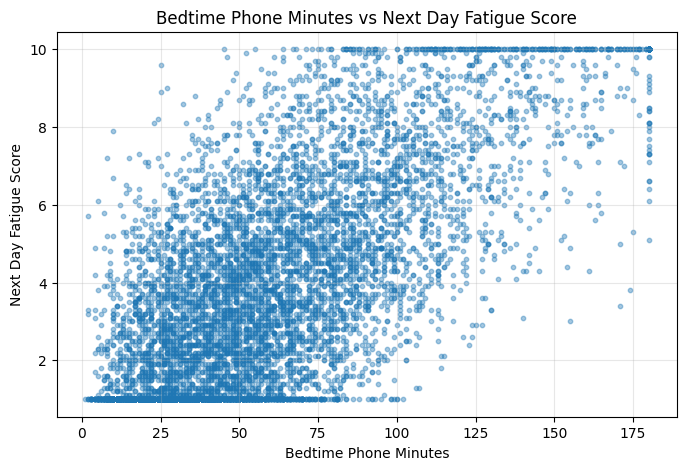

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(df[main_independent], df[dependent_var], alpha=0.4, s=10)
plt.title("Bedtime Phone Minutes vs Next Day Fatigue Score")
plt.xlabel("Bedtime Phone Minutes")
plt.ylabel("Next Day Fatigue Score")
plt.grid(alpha=0.3)
plt.show()

#### Box Plot

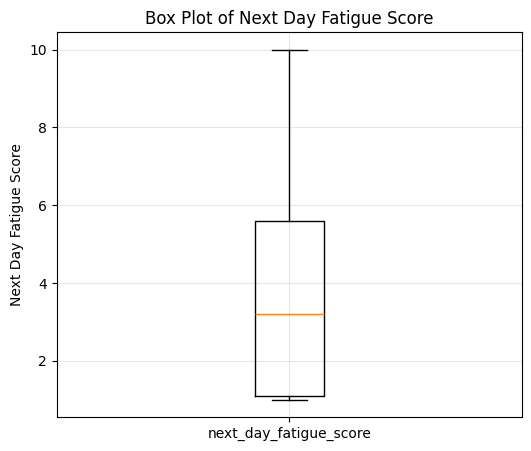

Number of outliers in next_day_fatigue_score : 0


In [15]:
plt.figure(figsize=(6, 5))
plt.boxplot(df[dependent_var])
plt.title("Box Plot of Next Day Fatigue Score")
plt.ylabel("Next Day Fatigue Score")
plt.xticks([1], ["next_day_fatigue_score"])
plt.grid(alpha=0.3)
plt.show()

# Outliers using IQR rule
Q1 = df[dependent_var].quantile(0.25)
Q3 = df[dependent_var].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df[dependent_var] < Q1 - 1.5 * IQR) | (df[dependent_var] > Q3 + 1.5 * IQR)]
print("Number of outliers in", dependent_var, ":", len(outliers))

#### Histogram

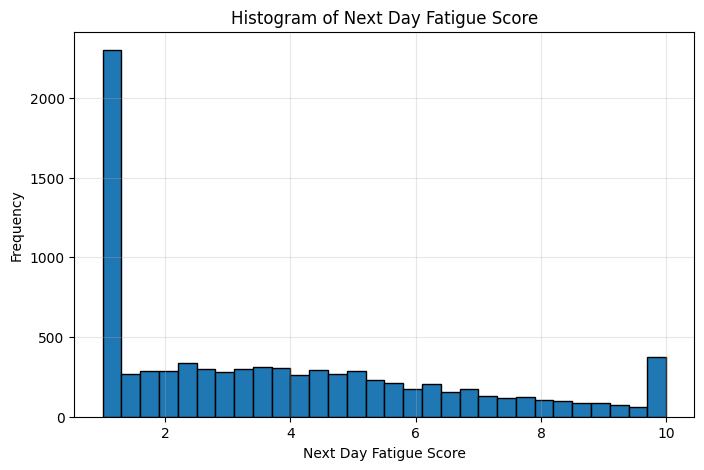

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df[dependent_var], bins=30, edgecolor="black")
plt.title("Histogram of Next Day Fatigue Score")
plt.xlabel("Next Day Fatigue Score")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

#### Heat Map

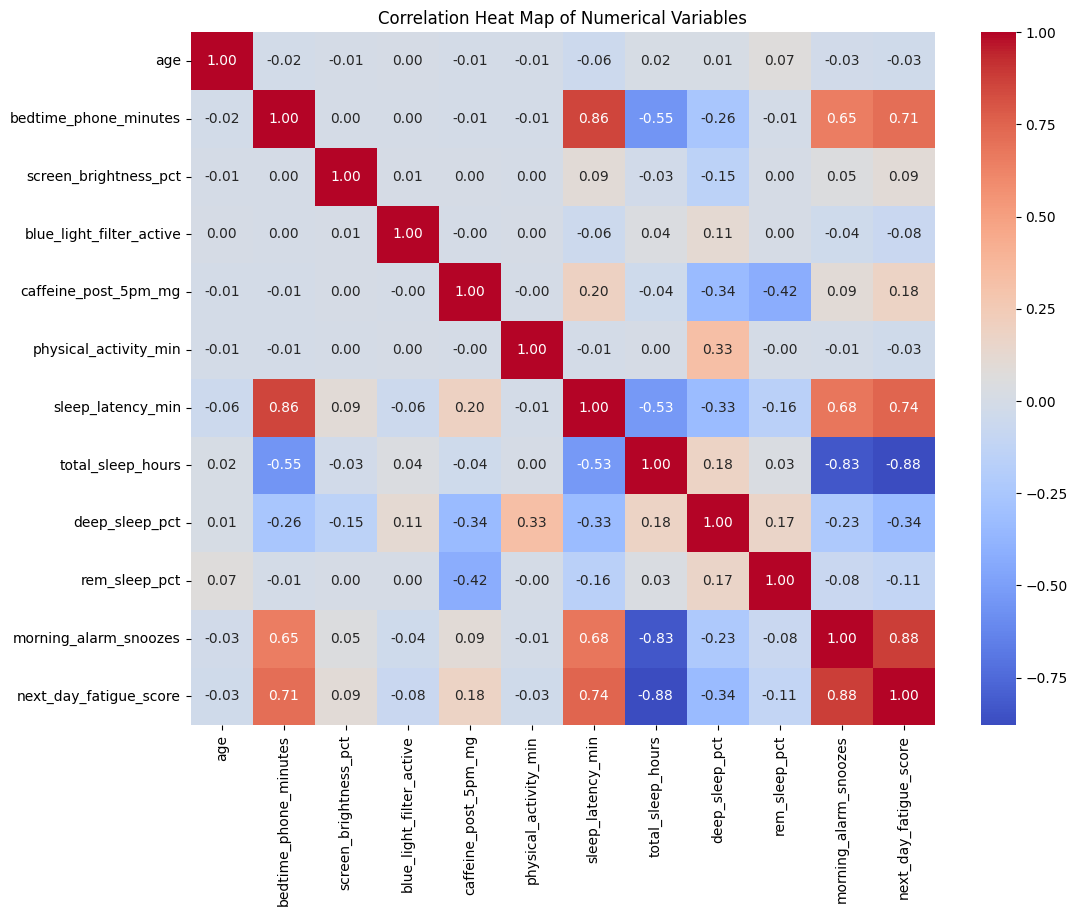

Correlation of each variable with next_day_fatigue_score :
morning_alarm_snoozes       0.881
sleep_latency_min           0.745
bedtime_phone_minutes       0.711
caffeine_post_5pm_mg        0.181
screen_brightness_pct       0.093
age                        -0.028
physical_activity_min      -0.029
blue_light_filter_active   -0.077
rem_sleep_pct              -0.115
deep_sleep_pct             -0.341
total_sleep_hours          -0.879
Name: next_day_fatigue_score, dtype: float64


In [17]:
plt.figure(figsize=(12, 9))
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heat Map of Numerical Variables")
plt.show()

print("Correlation of each variable with", dependent_var, ":")
print(corr_matrix[dependent_var].drop(dependent_var).sort_values(ascending=False).round(3))

### Hypothesis Test
**Numerical:** bedtime_phone_minutes vs next_day_fatigue_score (Pearson and Spearman)  
- H0: There is no correlation between bedtime phone minutes and next day fatigue score.  
- H1: There is a correlation between bedtime phone minutes and next day fatigue score.  

Significance level α = 0.05

In [18]:
alpha = 0.05

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(df[main_independent], df[dependent_var])
print("Pearson correlation coefficient (r):", round(pearson_r, 4))
print("Pearson p-value:", pearson_p)
if pearson_p < alpha:
    print("Result: Reject H0 - there is a significant linear correlation.")
else:
    print("Result: Fail to reject H0 - no significant linear correlation.")

# Spearman correlation
spearman_r, spearman_p = stats.spearmanr(df[main_independent], df[dependent_var])
print("\nSpearman correlation coefficient (rho):", round(spearman_r, 4))
print("Spearman p-value:", spearman_p)
if spearman_p < alpha:
    print("Result: Reject H0 - there is a significant monotonic correlation.")
else:
    print("Result: Fail to reject H0 - no significant monotonic correlation.")

Pearson correlation coefficient (r): 0.7105
Pearson p-value: 0.0
Result: Reject H0 - there is a significant linear correlation.

Spearman correlation coefficient (rho): 0.6654
Spearman p-value: 0.0
Result: Reject H0 - there is a significant monotonic correlation.


**Categorical:** sleep_debt_category vs fatigue level (Chi-Square)  
The fatigue score is grouped into three levels (Low, Medium, High) using equal-sized groups so it can be tested against a categorical variable.  
- H0: Sleep debt category and fatigue level are independent.  
- H1: Sleep debt category and fatigue level are associated.

In [19]:
df["fatigue_level"] = pd.qcut(df[dependent_var], q=3, labels=["Low", "Medium", "High"])

contingency_table = pd.crosstab(df["sleep_debt_category"], df["fatigue_level"])
print("Contingency Table:")
print(contingency_table)

chi2, chi_p, dof, expected = stats.chi2_contingency(contingency_table)
print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("p-value:", chi_p)
if chi_p < alpha:
    print("Result: Reject H0 - sleep debt category and fatigue level are associated.")
else:
    print("Result: Fail to reject H0 - no significant association.")

Contingency Table:
fatigue_level         Low  Medium  High
sleep_debt_category                    
Mild Deficit         1240     737    27
Moderate Debt         284    2074  2104
Optimal Recovery     1334      53     0
Severe Sleep Debt       0       0   647

Chi-square statistic: 6339.4856
Degrees of freedom: 6
p-value: 0.0
Result: Reject H0 - sleep debt category and fatigue level are associated.


### One Sample T-test
Checks whether the sample mean of next_day_fatigue_score is equal to the population mean.  
- H0: Sample mean = Population mean (sample is representative).  
- H1: Sample mean ≠ Population mean (sample is not representative).  

Significance level α = 0.05

In [20]:
population_mean = df[dependent_var].mean()
print("Population mean:", round(population_mean, 4))

for name, sample in [("Random Sample", random_sample), ("Systematic Sample", systematic_sample)]:
    t_stat, t_p = stats.ttest_1samp(sample[dependent_var], population_mean)
    print("\n" + name)
    print("Sample mean:", round(sample[dependent_var].mean(), 4))
    print("t-statistic:", round(t_stat, 4))
    print("p-value:", round(t_p, 4))
    if t_p < alpha:
        print("Result: Reject H0 - the sample is NOT representative of the population.")
    else:
        print("Result: Fail to reject H0 - the sample is representative of the population.")

Population mean: 3.7947

Random Sample
Sample mean: 3.648
t-statistic: -0.6922
p-value: 0.4899
Result: Fail to reject H0 - the sample is representative of the population.

Systematic Sample
Sample mean: 4.6107
t-statistic: 3.8367
p-value: 0.0002
Result: Reject H0 - the sample is NOT representative of the population.
